In [1]:
import uproot, awkward as ak, numpy as np, matplotlib.pyplot as plt
print(uproot.__version__, ak.__version__)

5.7.7 2.14.0


In [2]:
import uproot
file = uproot.open("/afs/cern.ch/work/f/frresend/MG5_aMC_v3_5_17/test_dy/Events/run_02/tag_1_delphes_events.root")
#print(file.keys())

In [3]:
delphes_events = file['Delphes;1']
#print(delphes_events.keys())
muon_events = delphes_events['Muon']
array_muon_events = muon_events.array()
print(array_muon_events)
#print(muon_events)
#print(delphes_events['Muon_size'])
muon_eta = muon_events['Muon.Eta']
muon_phi = muon_events['Muon.Phi']
muon_charge = muon_events['Muon.Charge']
muon_pt = muon_events['Muon.PT']
print(muon_eta)
#print(muon_events.keys())
#print(muon_events['Muon_Size'])
muon_events_eta_array = muon_eta.array()
muon_events_pt_array = muon_pt.array()
muon_events_charge_array = muon_charge.array()
muon_events_phi_array = muon_phi.array()
print(muon_events_eta_array, muon_events_pt_array, muon_events_charge_array, muon_events_phi_array)
values, counts = np.unique(muon_events, return_counts=True)
#plt.stairs(counts, bins)
print(values, counts)
print(counts[2]/(counts[0]+counts[1]+counts[2]))
print(counts[2]/(counts.sum()))

[2, 2, 1, 2, 2, 2, 2, 2, 2, 1, 2, 1, 1, ..., 2, 2, 2, 2, 2, 1, 2, 2, 2, 1, 1, 2]
<TBranchElement 'Muon.Eta' at 0x7f9cd5ca91f0>
[[1.4, -1.06], [-0.651, -2.48], [-1.49], ..., [1.4], [1.57], [0.694, 2.23]] [[29.2, 27.9], [33, 25.2], [35.4], [...], ..., [15.8], [41.3], [36.9, 32.2]] [[-1, 1], [-1, 1], [1], [1, -1], [-1, 1], ..., [1, -1], [1], [-1], [-1, 1]] [[-0.0189, 3.11], [1.46, -0.748], [-1.85], ..., [1.17], [2.94], [-0.846, 2.34]]
[0 1 2] [ 289 2892 6819]
0.6819
0.6819


In [6]:
mask = (ak.num(muon_events_pt_array) == 2) & (ak.sum(muon_events_charge_array, axis=1) == 0)

In [ ]:
muons = muon_events.arrays(["Muon.PT", "Muon.Eta", "Muon.Phi", "Muon.Charge"])
muons_sel = muons[mask]

muons_sel["Muon.PT"]   # pt of the selected events

[{'Muon.PT': [29.2, 27.9], 'Muon.Eta': [1.4, ...], 'Muon.Phi': [...], ...}, ...]


<Array [[29.2, 27.9], [33, ...], ..., [36.9, 32.2]] type='6819 * var * float32'>

In [20]:
print(muons_sel["Muon.PT"])

[[29.2, 27.9], [33, 25.2], [43.3, 43], ..., [...], [83.6, 22.2], [36.9, 32.2]]


In [8]:
ak.sum(mask)

np.int64(6819)

In [23]:
def to_cartesian(pt, phi, eta, m):
    px = pt*np.cos(phi)
    py = pt*np.sin(phi)
    pz = pt*np.sinh(eta)
    E = np.sqrt(px**2+py**2+pz**2+m**2)
    return E, px, py, pz

In [26]:
(["Muon.PT", "Muon.Eta", "Muon.Phi", "Muon.Charge"])
sel_pt = muons_sel["Muon.PT"]
sel_eta = muons_sel["Muon.Eta"]
sel_charge = muons_sel["Muon.Charge"]
sel_phi = muons_sel["Muon.Phi"]
E1, px1, py1, pz1 = to_cartesian(sel_pt[:, 0], sel_phi[:, 0],  sel_eta[:, 0],  sel_charge[:, 0] ) 
E2, px2, py2, pz2 = to_cartesian(sel_pt[:, 1], sel_phi[:, 1],  sel_eta[:, 1],  sel_charge[:, 1] ) 

In [27]:
E_tot = E1+E2
px_tot = px1+px2
py_tot = py1+py2
pz_tot = pz1+pz2
m_mumu = np.sqrt(E_tot**2-px_tot**2-py_tot**2-pz_tot**2)
pt_mumu = np.sqrt(px_tot**2+py_tot**2)

(array([   7.,    9.,   12.,   15.,   11.,   15.,   13.,   17.,   10.,
          21.,   10.,   12.,   18.,   13.,   10.,   26.,   26.,   26.,
          22.,   31.,   38.,   57.,   61.,   76.,  100.,  112.,  214.,
         308.,  490.,  780., 1000.,  991.,  790.,  462.,  261.,  140.,
         102.,   69.,   54.,   43.,   26.,   18.,   20.,   22.,   19.,
          10.,   10.,   19.,   13.,    7.,    9.,    7.,    8.,    6.,
           8.,    7.,    4.,    8.,    4.,    4.]),
 array([ 60.,  61.,  62.,  63.,  64.,  65.,  66.,  67.,  68.,  69.,  70.,
         71.,  72.,  73.,  74.,  75.,  76.,  77.,  78.,  79.,  80.,  81.,
         82.,  83.,  84.,  85.,  86.,  87.,  88.,  89.,  90.,  91.,  92.,
         93.,  94.,  95.,  96.,  97.,  98.,  99., 100., 101., 102., 103.,
        104., 105., 106., 107., 108., 109., 110., 111., 112., 113., 114.,
        115., 116., 117., 118., 119., 120.]),
 <BarContainer object of 60 artists>)

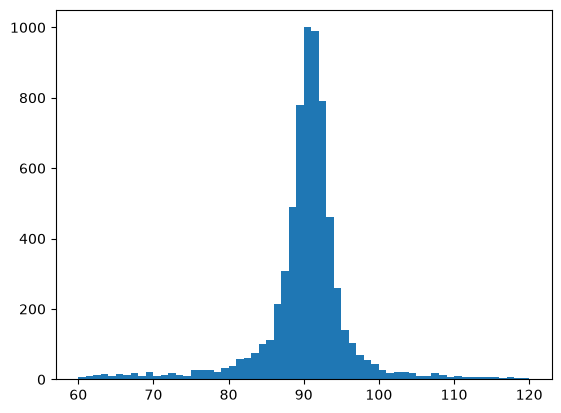

In [28]:
plt.hist(m_mumu, bins=60, range=(60, 120))

In [ ]:
plt.hist(pt_mumu, bins=60, range=(60, 120))